# Data exploration

In this notebook we will explore the provided data consisting of the wind forecast and power generation.

## Import necessary libraries

In [1]:
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import FeatureUnion
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error


# helper validation
from sklearn.utils.validation import check_is_fitted

import os
import tarfile
from six.moves import urllib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

## Load Data

In [2]:
path = "../Data/TrainData_A.csv"

def load_data(path):
    data = pd.read_csv(path)
    return data

wind = load_data(path)
wind.head(15)

,TIMESTAMP,POWER,U10,V10,U100,V100
0,20150101 00:00,NaN,NaN,NaN,NaN,NaN
1,20150101 01:00,NaN,6.24102,3.49613,9.73707,4.78492
2,20150101 02:00,NaN,5.62234,4.06239,8.94497,5.71768
3,20150101 03:00,0.666693,5.99531,4.89334,9.52143,6.99094
4,20150101 04:00,NaN,6.90809,4.79099,10.63280,6.75417
5,20150101 05:00,NaN,6.95268,4.83204,10.70080,6.74193
6,20150101 06:00,0.937501,6.17865,5.70277,9.73491,8.09731
7,20150101 07:00,NaN,7.63436,4.76415,11.73130,6.60519
8,20150101 08:00,NaN,7.32686,5.98271,11.28840,8.46992
9,20150101 09:00,0.935002,7.39201,5.66010,11.21580,8.10729


Attribute **one** is timestamps in YearMonthDay Hour:Minute <br> 
Attribute **two** is Power but we seem to only get a value every 3 hours. <br>
U10, V10, U100 and V100 are orthogonal wind-vector components at 10 and 100 meters respectively. So far they seem to give values at every hour. <br>
**U:** zonal (east-west) component with a positive value indicating wind *towards* the east. <br>
**V:** meriodional (north-south) component with positive value indicating wind *towards* the north.<br>
It is possible that converting this into polar coordinates with magnitude (wind speed) and radians (direction) will be helpful.

In [3]:
wind.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27049 entries, 0 to 27048
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TIMESTAMP  27049 non-null  object 
 1   POWER      26590 non-null  float64
 2   U10        27048 non-null  float64
 3   V10        27048 non-null  float64
 4   U100       27048 non-null  float64
 5   V100       27048 non-null  float64
dtypes: float64(5), object(1)
memory usage: 1.2+ MB


With the .info() method we easily see that power has a value for most timestamps, less than 2% are missing -- our previous assumption was incorrect and we will have to deal with this missing information. It could come from windfarm maintenance or other factors that forces power production to halt for some time. <br>
We also see that only one timestamp, the first, lacks a value for the wind vectors. Therefore we should be able to safely remove the first row since it contains no valuable data.

In [4]:
wind = wind.iloc[1:].reset_index(drop=True)
wind.head(2)

,TIMESTAMP,POWER,U10,V10,U100,V100
0,20150101 01:00,NaN,6.24102,3.49613,9.73707,4.78492
1,20150101 02:00,NaN,5.62234,4.06239,8.94497,5.71768


Now we should investigate the missing power gaps.

In [5]:
print(wind['POWER'].isna().sum())

458


458 NaN values in the POWER attribute. Plot missing values over time to see if it looks systemic. First change the TIMESTAMP attribute to Pandas datetime64[ns] type.

In [6]:
wind['TIMESTAMP'] = pd.to_datetime(wind['TIMESTAMP'], format='%Y%m%d %H:%M')
wind.info()
wind.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27048 entries, 0 to 27047
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   TIMESTAMP  27048 non-null  datetime64[ns]
 1   POWER      26590 non-null  float64       
 2   U10        27048 non-null  float64       
 3   V10        27048 non-null  float64       
 4   U100       27048 non-null  float64       
 5   V100       27048 non-null  float64       
dtypes: datetime64[ns](1), float64(5)
memory usage: 1.2 MB


,TIMESTAMP,POWER,U10,V10,U100,V100
0,2015-01-01 01:00:00,NaN,6.24102,3.49613,9.73707,4.78492
1,2015-01-01 02:00:00,NaN,5.62234,4.06239,8.94497,5.71768
2,2015-01-01 03:00:00,0.666693,5.99531,4.89334,9.52143,6.99094
3,2015-01-01 04:00:00,NaN,6.90809,4.79099,10.63280,6.75417
4,2015-01-01 05:00:00,NaN,6.95268,4.83204,10.70080,6.74193


We see that the type now has changed and we can inspect how it looks in the column.
<br>
Now we should be able to plot POWER(TIMESTAMP)

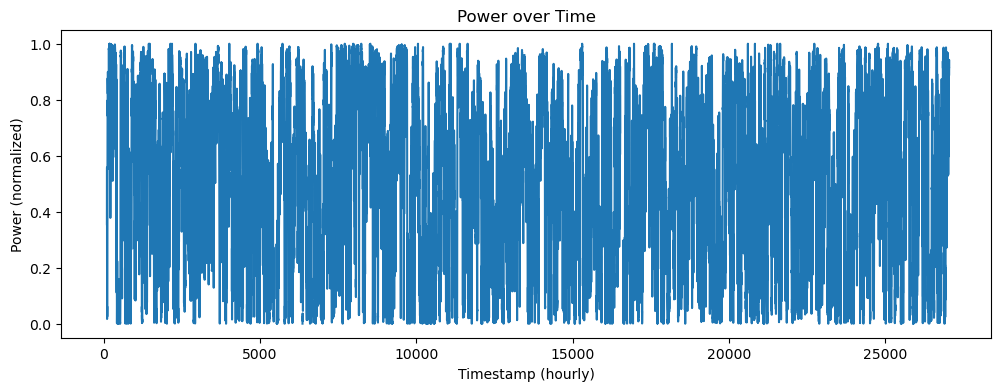

In [7]:
fig, ax = plt.subplots(figsize=(12, 4), linewidth=0.2, alpha=0.4)
wind['POWER'].plot(ax=ax)
ax.set_title('Power over Time')
ax.set_ylabel('Power (normalized)')
ax.set_xlabel('Timestamp (hourly)')
plt.show()

This doesn't help much to find a pattern. Plot where there are missing values instead. It does get clear though that power goes from 0-1 where 0 is (presumably) no power and 1 is full power.

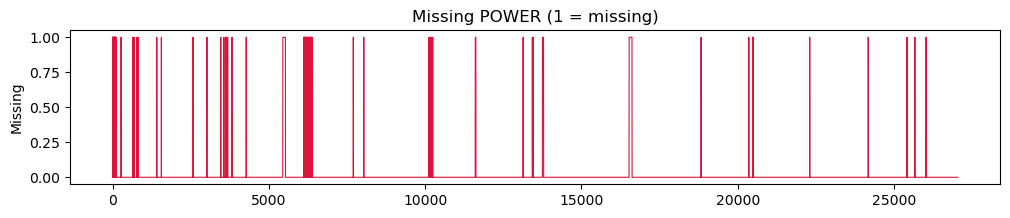

In [8]:
wind['POWER'].isna().astype(int).plot(figsize=(12, 2), linewidth=0.8, color='crimson', title='Missing POWER (1 = missing)')
plt.ylabel('Missing')
plt.show()

## Data cleaning

There is no obvious pattern here. I believe it is safe to estimate these values. <br><br> 
There are different approaches to this:<br> 
**Persistence fill:** whenever POWER is NaN, replace with previous valid value. <br>
**Moving-average fill:** to smooth noise, take average of last *m* hours. <br>
**Hourly climatology:** compute the mean power per hour-of-day over recent days; plug those values for missing values in the same time-stamp hour. <br>
<br>
Three versions of TrainData will be created, with the name 'wind_*method*'. The methods will be shorted with **persistance**, **average** and **hourly** for the three types of methods.

### Persistance fill


In [9]:
wind_persistance = wind.copy()
wind_persistance['POWER'] = wind_persistance['POWER'].ffill().bfill()
wind_persistance.head(10)

,TIMESTAMP,POWER,U10,V10,U100,V100
0,2015-01-01 01:00:00,0.666693,6.24102,3.49613,9.73707,4.78492
1,2015-01-01 02:00:00,0.666693,5.62234,4.06239,8.94497,5.71768
2,2015-01-01 03:00:00,0.666693,5.99531,4.89334,9.52143,6.99094
3,2015-01-01 04:00:00,0.666693,6.90809,4.79099,10.63280,6.75417
4,2015-01-01 05:00:00,0.666693,6.95268,4.83204,10.70080,6.74193
5,2015-01-01 06:00:00,0.937501,6.17865,5.70277,9.73491,8.09731
6,2015-01-01 07:00:00,0.937501,7.63436,4.76415,11.73130,6.60519
7,2015-01-01 08:00:00,0.937501,7.32686,5.98271,11.28840,8.46992
8,2015-01-01 09:00:00,0.935002,7.39201,5.66010,11.21580,8.10729
9,2015-01-01 10:00:00,0.935002,7.81017,5.22474,11.80900,7.32732


Looks like it has achieved what we wanted. Lets double check for any NaN values.

In [10]:
wind_persistance['POWER'].isna().sum()

0

All rows have a non-NaN value.

### Moving-average fill

In [11]:
wind_average = wind.copy()

m = 5       ## MOVING AVERAGE OF THE M LAST HOURS, adjust this to balance models

rolling_mean = (
    wind_average['POWER']
    .rolling(window=m, min_periods=1)
    .mean()
)

wind_average['POWER'] = wind_average['POWER'].fillna(rolling_mean)
wind_average.head(20)

,TIMESTAMP,POWER,U10,V10,U100,V100
0,2015-01-01 01:00:00,NaN,6.24102,3.49613,9.73707,4.78492
1,2015-01-01 02:00:00,NaN,5.62234,4.06239,8.94497,5.71768
2,2015-01-01 03:00:00,0.666693,5.99531,4.89334,9.52143,6.99094
3,2015-01-01 04:00:00,0.666693,6.90809,4.79099,10.63280,6.75417
4,2015-01-01 05:00:00,0.666693,6.95268,4.83204,10.70080,6.74193
5,2015-01-01 06:00:00,0.937501,6.17865,5.70277,9.73491,8.09731
6,2015-01-01 07:00:00,0.802097,7.63436,4.76415,11.73130,6.60519
7,2015-01-01 08:00:00,0.937501,7.32686,5.98271,11.28840,8.46992
8,2015-01-01 09:00:00,0.935002,7.39201,5.66010,11.21580,8.10729
9,2015-01-01 10:00:00,0.936251,7.81017,5.22474,11.80900,7.32732


For row 0 and 1 we are missing values due to there being no first point to linearize with. Lets check if there are more missing values:

In [12]:
wind_average['POWER'].isna().sum()

248

This will differ depending on the value of *m*, but with m = 5 POWER is missing 248 values. We will take care of these by filling in with the functions ffill() and bfill(). <br>
bfill() handles the opening gap by copying the first valid value backward; ffill() then catches anything in between.

In [13]:
wind_average['POWER'] = wind_average['POWER'].ffill().bfill()
wind_average.head()

,TIMESTAMP,POWER,U10,V10,U100,V100
0,2015-01-01 01:00:00,0.666693,6.24102,3.49613,9.73707,4.78492
1,2015-01-01 02:00:00,0.666693,5.62234,4.06239,8.94497,5.71768
2,2015-01-01 03:00:00,0.666693,5.99531,4.89334,9.52143,6.99094
3,2015-01-01 04:00:00,0.666693,6.90809,4.79099,10.63280,6.75417
4,2015-01-01 05:00:00,0.666693,6.95268,4.83204,10.70080,6.74193


In [14]:
wind_average['POWER'].isna().sum()

0

Now there are no NaN values.

### Hourly climatology

In [15]:
wind_hourly = wind.copy()
hourly_means = wind_hourly.groupby(wind_hourly['TIMESTAMP'].dt.hour)['POWER'].mean()
hourly_means    # Series with mean POWER for each hour of the day

TIMESTAMP
0     0.514555
1     0.509696
2     0.505619
3     0.511900
4     0.503110
5     0.507338
6     0.514493
7     0.515249
8     0.518379
9     0.529944
10    0.531480
11    0.537485
12    0.544924
13    0.544830
14    0.540171
15    0.537040
16    0.524717
17    0.520302
18    0.515628
19    0.510324
20    0.504638
21    0.508554
22    0.508014
23    0.513489
Name: POWER, dtype: float64

In [16]:
# Fill missing POWER values based on hourly means
wind_hourly['POWER'] = wind_hourly['POWER'].fillna(hourly_means).ffill().bfill()
wind_hourly.head(10)

,TIMESTAMP,POWER,U10,V10,U100,V100
0,2015-01-01 01:00:00,0.514555,6.24102,3.49613,9.73707,4.78492
1,2015-01-01 02:00:00,0.509696,5.62234,4.06239,8.94497,5.71768
2,2015-01-01 03:00:00,0.666693,5.99531,4.89334,9.52143,6.99094
3,2015-01-01 04:00:00,0.511900,6.90809,4.79099,10.63280,6.75417
4,2015-01-01 05:00:00,0.503110,6.95268,4.83204,10.70080,6.74193
5,2015-01-01 06:00:00,0.937501,6.17865,5.70277,9.73491,8.09731
6,2015-01-01 07:00:00,0.514493,7.63436,4.76415,11.73130,6.60519
7,2015-01-01 08:00:00,0.515249,7.32686,5.98271,11.28840,8.46992
8,2015-01-01 09:00:00,0.935002,7.39201,5.66010,11.21580,8.10729
9,2015-01-01 10:00:00,0.529944,7.81017,5.22474,11.80900,7.32732


We can manually see that the previous empty rows now contain their hourly average seen in the hourly_means series above. Lets check for any NaN values.

In [17]:
wind_hourly['POWER'].isna().sum()

0

Also 0, great!

## Polar coordinates

As stated before, it could be helpful to convert the vectors **u** and **v** into the polar coordinate equivilent. With that information we can make graphs that plot, for example, magnitude (wind speed) against time on different time-scales. With this we can try to make out patterns manually before giving the data to models.

**Define a function** that converts to polar

In [18]:
def convert_to_polar(wind):
    wind['wind_speed_10m'] = np.sqrt(wind['U10']**2 + wind['V10']**2)          ##length of hypotenuse, magnitude  
    wind['wind_direction_10m'] = np.arctan2(wind['V10'], wind['U10']) * (180 / np.pi)
    wind['wind_direction_10m'] = (wind[f'wind_direction_10m'] + 360) % 360

    wind['wind_speed_100m'] = np.sqrt(wind['U100']**2 + wind['V100']**2)
    wind['wind_direction_100m'] = np.arctan2(wind['V100'], wind['U100']) * (180 / np.pi)
    wind['wind_direction_100m'] = (wind[f'wind_direction_100m'] + 360) % 360
    return wind

**Polar coordinate legend** <br>
0° = wind going to east <br>
90° = wind going to north <br>
180° = wind going to west <br>
270° = wind going to south

Apply it to wind_persistance and create a new copy with the polar coordinates.

In [19]:
wind_persistance_polar = convert_to_polar(wind_persistance)
wind_persistance_polar = wind_persistance_polar.drop(columns=['U10', 'V10', 'U100', 'V100'])
wind_persistance_polar.head(10)

,TIMESTAMP,POWER,wind_speed_10m,wind_direction_10m,wind_speed_100m,wind_direction_100m
0,2015-01-01 01:00:00,0.666693,7.153548,29.256924,10.849239,26.170089
1,2015-01-01 02:00:00,0.666693,6.936405,35.849781,10.616231,32.586965
2,2015-01-01 03:00:00,0.666693,7.738767,39.221140,11.812319,36.287312
3,2015-01-01 04:00:00,0.666693,8.406860,34.742594,12.596636,32.424540
4,2015-01-01 05:00:00,0.666693,8.466898,34.798897,12.647559,32.212561
5,2015-01-01 06:00:00,0.937501,8.408169,42.706390,12.662342,39.753030
6,2015-01-01 07:00:00,0.937501,8.998921,31.965834,13.462984,29.381247
7,2015-01-01 08:00:00,0.937501,9.459159,39.233181,14.112672,36.881655
8,2015-01-01 09:00:00,0.935002,9.310131,37.441466,13.839159,35.861114
9,2015-01-01 10:00:00,0.935002,9.396630,33.781186,13.897557,31.819025


Repeat for wind_average and wind_hourly

In [20]:
wind_average_polar = convert_to_polar(wind_average)
wind_average_polar = wind_average_polar.drop(columns=['U10', 'V10', 'U100', 'V100'])
wind_average_polar.head(10)

,TIMESTAMP,POWER,wind_speed_10m,wind_direction_10m,wind_speed_100m,wind_direction_100m
0,2015-01-01 01:00:00,0.666693,7.153548,29.256924,10.849239,26.170089
1,2015-01-01 02:00:00,0.666693,6.936405,35.849781,10.616231,32.586965
2,2015-01-01 03:00:00,0.666693,7.738767,39.221140,11.812319,36.287312
3,2015-01-01 04:00:00,0.666693,8.406860,34.742594,12.596636,32.424540
4,2015-01-01 05:00:00,0.666693,8.466898,34.798897,12.647559,32.212561
5,2015-01-01 06:00:00,0.937501,8.408169,42.706390,12.662342,39.753030
6,2015-01-01 07:00:00,0.802097,8.998921,31.965834,13.462984,29.381247
7,2015-01-01 08:00:00,0.937501,9.459159,39.233181,14.112672,36.881655
8,2015-01-01 09:00:00,0.935002,9.310131,37.441466,13.839159,35.861114
9,2015-01-01 10:00:00,0.936251,9.396630,33.781186,13.897557,31.819025


In [21]:
wind_hourly_polar = convert_to_polar(wind_hourly)
wind_hourly_polar = wind_hourly_polar.drop(columns=['U10', 'V10', 'U100', 'V100'])
wind_hourly_polar.head(10)

,TIMESTAMP,POWER,wind_speed_10m,wind_direction_10m,wind_speed_100m,wind_direction_100m
0,2015-01-01 01:00:00,0.514555,7.153548,29.256924,10.849239,26.170089
1,2015-01-01 02:00:00,0.509696,6.936405,35.849781,10.616231,32.586965
2,2015-01-01 03:00:00,0.666693,7.738767,39.221140,11.812319,36.287312
3,2015-01-01 04:00:00,0.511900,8.406860,34.742594,12.596636,32.424540
4,2015-01-01 05:00:00,0.503110,8.466898,34.798897,12.647559,32.212561
5,2015-01-01 06:00:00,0.937501,8.408169,42.706390,12.662342,39.753030
6,2015-01-01 07:00:00,0.514493,8.998921,31.965834,13.462984,29.381247
7,2015-01-01 08:00:00,0.515249,9.459159,39.233181,14.112672,36.881655
8,2015-01-01 09:00:00,0.935002,9.310131,37.441466,13.839159,35.861114
9,2015-01-01 10:00:00,0.529944,9.396630,33.781186,13.897557,31.819025


### Processing WeatherForecastInput_A
Repeat all the steps for the input data so both datasets are of the same structure.

In [22]:
# Load weather input data
path = "../Data/WeatherForecastInput_A.csv"

def load_data(path):
    data = pd.read_csv(path)
    return data

weather_input = load_data(path)

# Change TIMESTAMP to datetime64 type
weather_input['TIMESTAMP'] = pd.to_datetime(wind['TIMESTAMP'], format='%Y%m%d %H:%M')
weather_input.info()
weather_input.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 672 entries, 0 to 671
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   TIMESTAMP  672 non-null    datetime64[ns]
 1   U10        672 non-null    float64       
 2   V10        672 non-null    float64       
 3   U100       672 non-null    float64       
 4   V100       672 non-null    float64       
dtypes: datetime64[ns](1), float64(4)
memory usage: 26.4 KB


,TIMESTAMP,U10,V10,U100,V100
0,2015-01-01 01:00:00,9.60919,4.04354,12.6693,5.03529
1,2015-01-01 02:00:00,9.57399,3.77546,12.8291,4.84658
2,2015-01-01 03:00:00,9.07057,3.79365,12.0920,4.75025
3,2015-01-01 04:00:00,8.03763,4.81464,11.0656,6.14977
4,2015-01-01 05:00:00,8.12874,5.13294,11.1379,6.57495


In [23]:
# Transfer wind data into polar coorinates
weather_input_polar = convert_to_polar(weather_input)
weather_input_polar = weather_input_polar.drop(columns=['U10', 'V10', 'U100', 'V100'])
weather_input_polar.head(10)

,TIMESTAMP,wind_speed_10m,wind_direction_10m,wind_speed_100m,wind_direction_100m
0,2015-01-01 01:00:00,10.425294,22.821322,13.633243,21.674865
1,2015-01-01 02:00:00,10.291520,21.521575,13.714049,20.695572
2,2015-01-01 03:00:00,9.831939,22.696497,12.991587,21.447003
3,2015-01-01 04:00:00,9.369325,30.922131,12.659667,29.063365
4,2015-01-01 05:00:00,9.613713,32.270600,12.933785,30.554298
5,2015-01-01 06:00:00,9.582052,34.422011,12.885632,32.820777
6,2015-01-01 07:00:00,9.840538,34.817951,13.252876,33.125181
7,2015-01-01 08:00:00,9.492422,32.135066,12.705568,30.550501
8,2015-01-01 09:00:00,9.278148,35.488030,12.449825,33.546102
9,2015-01-01 10:00:00,9.953094,40.772352,13.244172,38.590928


## Wind data plotting

### Power vs. wind speed

Plotting all 3 interpolated power data at 10m and 100m.

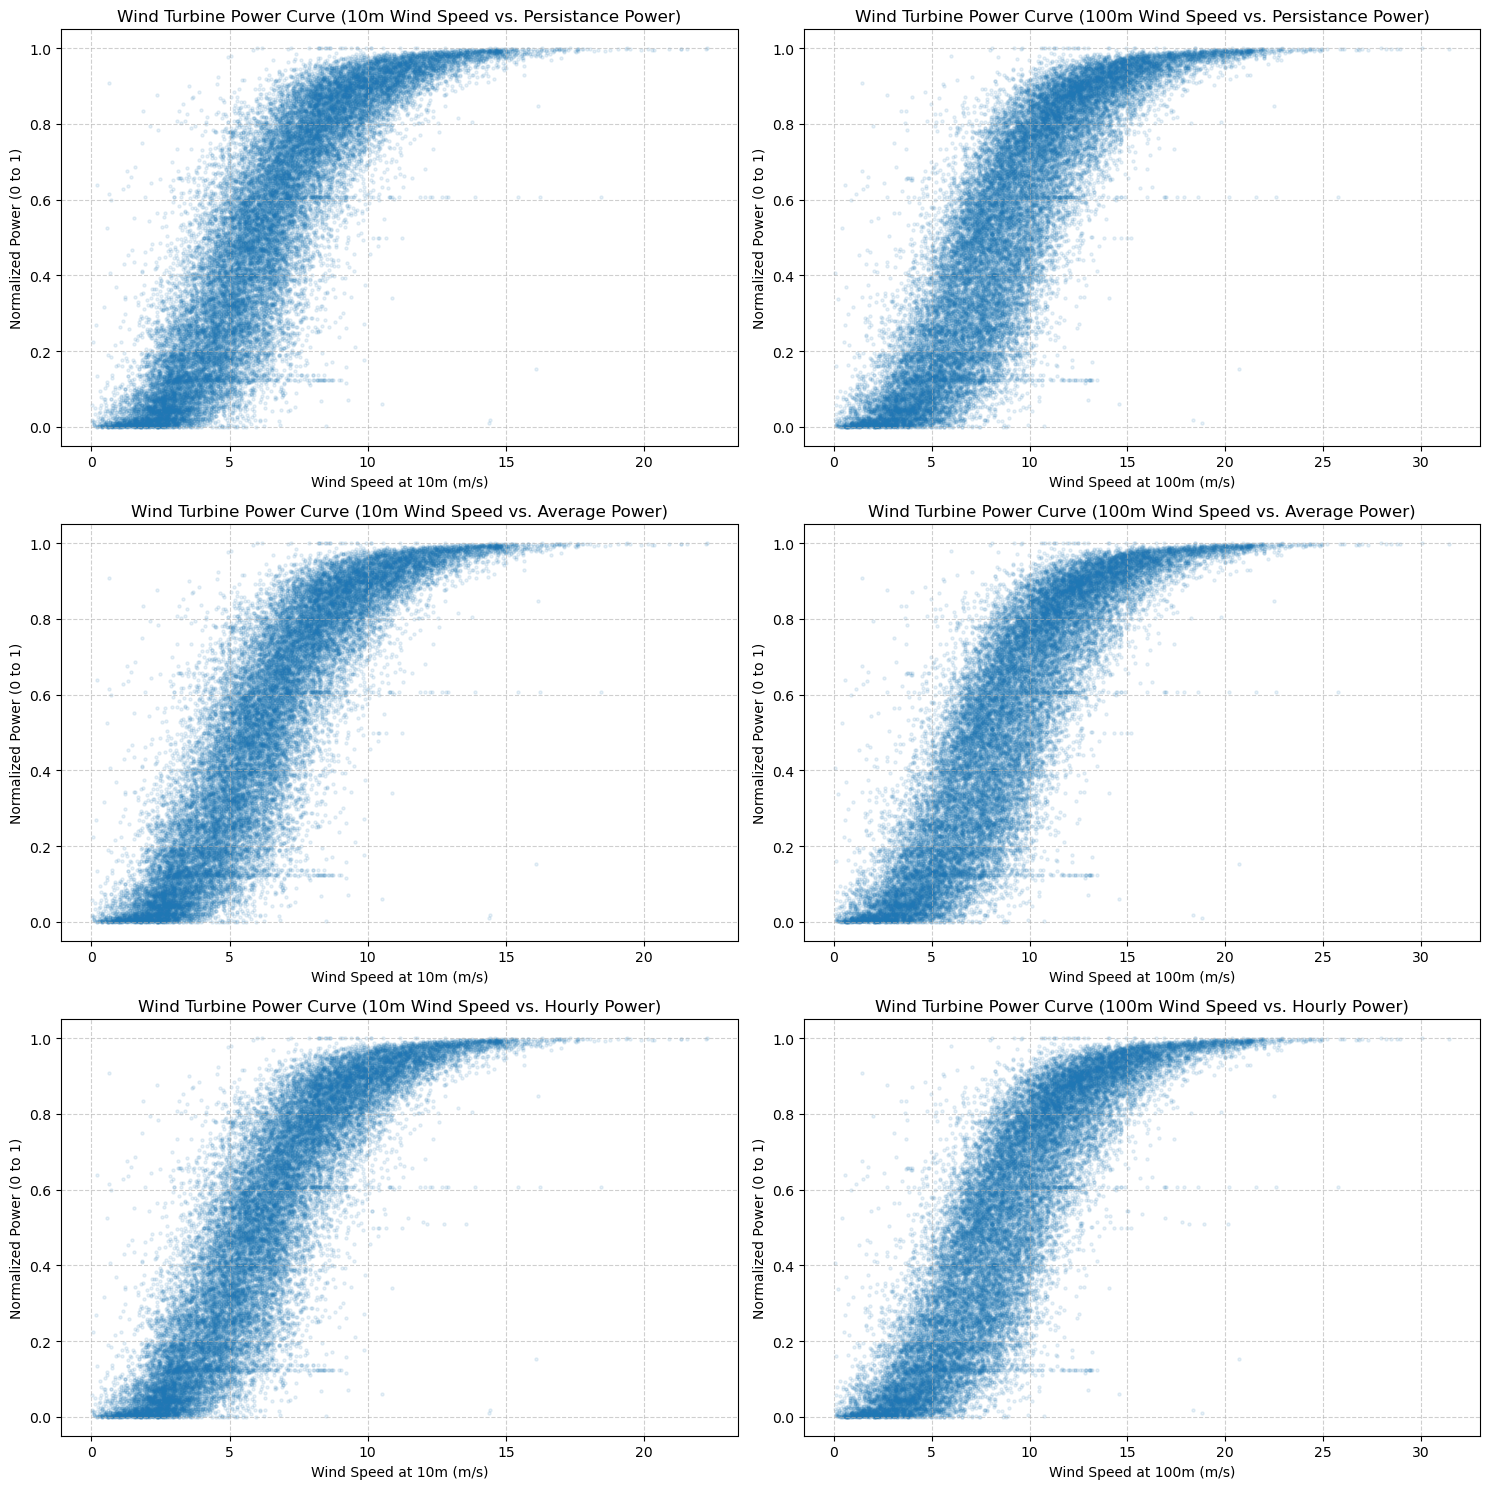

In [24]:
plt.figure(figsize=(15, 15))

# Plot 1: persistance data at 10m
plt.subplot(3, 2, 1)
plt.scatter(
    wind_persistance_polar['wind_speed_10m'],
    wind_persistance_polar['POWER'],
    alpha=0.1,   
    s=5     
)
plt.title('Wind Turbine Power Curve (10m Wind Speed vs. Persistance Power)')
plt.xlabel('Wind Speed at 10m (m/s)')
plt.ylabel('Normalized Power (0 to 1)')
plt.grid(True, linestyle='--', alpha=0.6)

# Plot 2: persistance data at 100m
plt.subplot(3, 2, 2)
plt.scatter(
    wind_persistance_polar['wind_speed_100m'],
    wind_persistance_polar['POWER'],
    alpha=0.1,   
    s=5     
)
plt.title('Wind Turbine Power Curve (100m Wind Speed vs. Persistance Power)')
plt.xlabel('Wind Speed at 100m (m/s)')
plt.ylabel('Normalized Power (0 to 1)')
plt.grid(True, linestyle='--', alpha=0.6)

# Plot 3: average data at 10m
plt.subplot(3, 2, 3)
plt.scatter(
    wind_average_polar['wind_speed_10m'],
    wind_average_polar['POWER'],
    alpha=0.1,   
    s=5     
)
plt.title('Wind Turbine Power Curve (10m Wind Speed vs. Average Power)')
plt.xlabel('Wind Speed at 10m (m/s)')
plt.ylabel('Normalized Power (0 to 1)')
plt.grid(True, linestyle='--', alpha=0.6)


# Plot 4: average data at 100m
plt.subplot(3, 2, 4)
plt.scatter(
    wind_average_polar['wind_speed_100m'],
    wind_average_polar['POWER'],
    alpha=0.1,   
    s=5     
)
plt.title('Wind Turbine Power Curve (100m Wind Speed vs. Average Power)')
plt.xlabel('Wind Speed at 100m (m/s)')
plt.ylabel('Normalized Power (0 to 1)')
plt.grid(True, linestyle='--', alpha=0.6)

# Plot 5: hourly data at 10m
plt.subplot(3, 2, 5)
plt.scatter(
    wind_hourly_polar['wind_speed_10m'],
    wind_hourly_polar['POWER'],
    alpha=0.1,   
    s=5     
)
plt.title('Wind Turbine Power Curve (10m Wind Speed vs. Hourly Power)')
plt.xlabel('Wind Speed at 10m (m/s)')
plt.ylabel('Normalized Power (0 to 1)')
plt.grid(True, linestyle='--', alpha=0.6)

# Plot 6: hourly data at 100m
plt.subplot(3, 2, 6)
plt.scatter(
    wind_hourly_polar['wind_speed_100m'],
    wind_hourly_polar['POWER'],
    alpha=0.1,   
    s=5     
)
plt.title('Wind Turbine Power Curve (100m Wind Speed vs. Hourly Power)')
plt.xlabel('Wind Speed at 100m (m/s)')
plt.ylabel('Normalized Power (0 to 1)')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

**Scatter Plot Analysis**<br><br>

All plots show a similar **"S" shaped power curve**. <br>
**Cut-in Speed** (wind speed at which power rises above 0) and **Rated Speed** (wind speed at which power first hits max) can be estimated. <br>
No **Cut-out Speed** (wind speed at which power drops back to 0) is visible. <br>
The difference between the 3 differently interpolated power data is not visible, as only 2% of the data was missing. <br>
Between to data at 10m and 100m seems to be shifted by 3-5 m/s, but nothing unusual. <br>
Generally I (Jonas) would focus on the wind speeds at 100m as thats generally closer to the hub heigt of the turbine, maybe we can explore later if it makes a difference, when dropping the 10m speeds.

### Correlation Heatmap

Quantitative overview of the linear relationships between all the variable. Persistance data chosen.

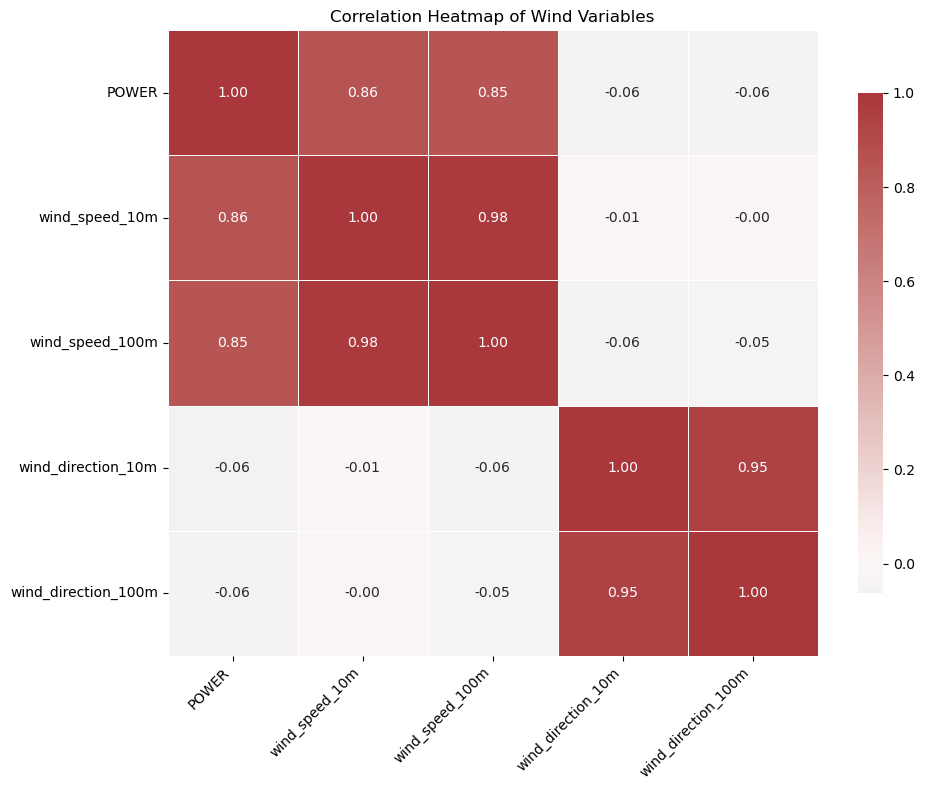

In [25]:
# 1. Define the columns you want to correlate
columns_to_correlate = [
    'POWER',
    'wind_speed_10m',
    'wind_speed_100m',
    'wind_direction_10m',
    'wind_direction_100m'
]

# 2. Calculate the correlation matrix
corr_matrix = wind_persistance_polar[columns_to_correlate].corr()
corr_matrix = wind_average_polar[columns_to_correlate].corr()

# 3. Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,      # Show the correlation values on the heatmap
    fmt='.2f',       # Format the values to 2 decimal places
    cmap='vlag',     # Use a diverging color map (blue-white-red)
    center=0,        # Center the color map at 0
    linewidths=.5,   # Add thin lines between cells
    cbar_kws={"shrink": .8} # Make the color bar a bit smaller
)

# Add labels and a title for clarity
plt.title('Correlation Heatmap of Wind Variables')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

# Ensure the plot layout is tight
plt.tight_layout()

# Display the plot
plt.show()

**Correlation Heatmap Analysis**

Very positive correlation between POWER and wind_speed (similar at 10m and 100m). <br>
Correlation between wind_speed_10m and wind_speed_100m almost 100 -> doesn't really matter what we use. <br>
Very low correlation between POWER and wind_direction -> no linear relationship between wind_direction and POWER. <br>
Correlation between wind_direction_10m and wind_direction_100m almost 100 -> wind direction consistent between the altitudes. <br><br>

=> wind speed ist the strongest predicter for POWER. No matter 10m or 100m.


### Wind Direction Polar Plot

Confirm that there is no correlation between the wind direction and power.

/tmp/ipykernel_15156/3642145005.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(['0.2', '0.4', '0.6', '0.8', '1.0'])


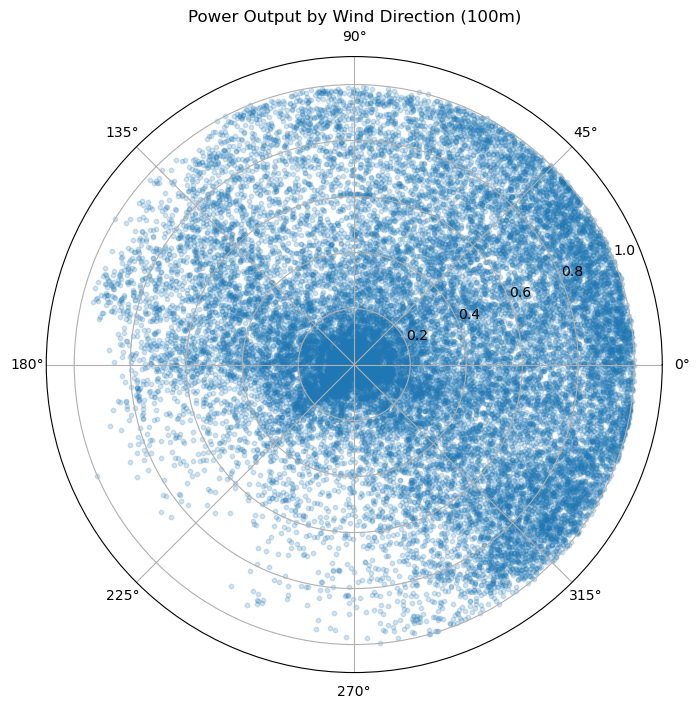

/tmp/ipykernel_15156/3642145005.py:87: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(['0.2', '0.4', '0.6', '0.8', '1.0'])


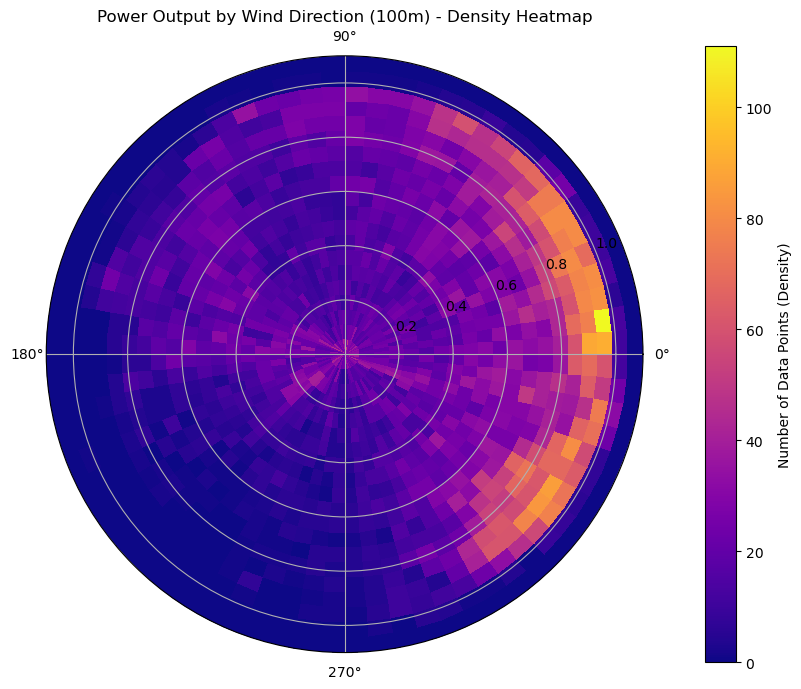

In [26]:
# 1. Convert wind direction from degrees to radians for plotting
# Matplotlib's polar plot expects angles in radians
theta = wind_persistance_polar['wind_direction_100m'] * np.pi / 180.0
radius = wind_persistance_polar['POWER']

# 2. Create the polar plot
plt.figure(figsize=(10, 8))
# Use subplot(projection='polar')
ax = plt.subplot(111, projection='polar')

# 3. Create the scatter plot
# The angle (theta) is the first argument, radius (power) is the second
ax.scatter(
    theta,
    radius,
    alpha=0.2, # Use a very low alpha to see density
    s=10
)

# 4. Configure the plot for wind direction
# ax.set_theta_zero_location('N')  # Set 0 degrees (North) to the top
# ax.set_theta_direction(-1)       # Set angles to go clockwise

# 5. Add a title
plt.title('Power Output by Wind Direction (100m)')

# Set the radial (power) limits
ax.set_rlim(0, 1.1)
ax.set_rlabel_position(22.5) # Move radial labels to not overlap
ax.set_yticklabels(['0.2', '0.4', '0.6', '0.8', '1.0'])

# Display the plot
plt.show()




# 1. Convert wind direction from degrees to radians for plotting
# Matplotlib's polar plot expects angles in radians
theta = wind_persistance_polar['wind_direction_100m'] * np.pi / 180.0
radius = wind_persistance_polar['POWER']

# 2. Create the polar plot
plt.figure(figsize=(10, 8)) # Made figure wider to accommodate the color bar
# Use subplot(projection='polar')
ax = plt.subplot(111, projection='polar')

# 3. --- NEW: Create 2D Histogram for Density ---
# Define the bins
N_theta_bins = 72  # One bin every 5 degrees
N_radius_bins = 20 # Bins for power
theta_bins = np.linspace(0.0, 2 * np.pi, N_theta_bins + 1)
radius_bins = np.linspace(0.0, 1.1, N_radius_bins + 1) # from 0 to max power (1.1)

# Calculate the 2D histogram
# This counts how many points fall into each (theta, radius) bin
density, _, _ = np.histogram2d(theta, radius, bins=(theta_bins, radius_bins))

# Transpose density for pcolormesh
# np.histogram2d bins[0] = x (theta), bins[1] = y (radius)
# pcolormesh expects Z[y, x]
density = density.T


# 4. --- REPLACED: Plot the density heatmap ---
# We use pcolormesh instead of scatter.
# This colors each bin based on the 'density' (count)
c = ax.pcolormesh(
    theta_bins,
    radius_bins,
    density,
    cmap='plasma',    # A good colormap for density: 'viridis', 'plasma', 'inferno'
    shading='auto'  # Use 'auto' or 'flat' to avoid warnings
)

# 5. Add a title
plt.title('Power Output by Wind Direction (100m) - Density Heatmap')

# Set the radial (power) limits
ax.set_rlim(0, 1.1)
# Add labels for the angles (0=E, 90=N, 180=W, 270=S)
ax.set_xticks(np.pi/180. * np.array([0, 90, 180, 270]))
ax.set_xticklabels(['0°', '90°', '180°', '270°'])

# Set radius labels
ax.set_rlabel_position(22.5) # Move radial labels to not overlap
ax.set_yticklabels(['0.2', '0.4', '0.6', '0.8', '1.0'])

# 7. --- NEW: Add a color bar ---
# This adds a legend that shows what the colors mean
plt.colorbar(c, ax=ax, label='Number of Data Points (Density)', pad=0.08)

# Display the plot
plt.show()

**Wind Direction Analysis**



## Summary
Jonathan:<br>
From the file TrainData_A I have created 6 different copies.<br>
3 of these are vector based and use 3 different fill functions for the missing POWER values. <br>
The remaining 3 are the polar coordinate equivalent in order to explore the data visually.

Jonas:<br>
From the file WeatherForecastInput_A I created 2 copies having the same structure as the training data. One in u-v coordinates and one in polar coordinates.

**Below cell creates a subfolder in /Data/ with the 8 new processed files.**

In [27]:
from pathlib import Path

output_dir = Path("../Data/Processed/")
output_dir.mkdir(parents=True, exist_ok=True)
wind_persistance.to_csv(output_dir / "wind_persistance.csv", index=False)
wind_average.to_csv(output_dir / "wind_average.csv", index=False)
wind_hourly.to_csv(output_dir / "wind_hourly.csv", index=False)
wind_persistance_polar.to_csv(output_dir / "wind_persistance_polar.csv", index=False)
wind_average_polar.to_csv(output_dir / "wind_average_polar.csv", index=False)
wind_hourly_polar.to_csv(output_dir / "wind_hourly_polar.csv", index=False)

weather_input.to_csv(output_dir / "weather_input.csv", index=False)
weather_input_polar.to_csv(output_dir / "weather_input_polar.csv", index=False)